# Prototipo: búsqueda de rutas seguras en una zona inundada

Este notebook implementa y compara **BFS, Dijkstra y A\*** en matrices de 10×10 o mayores.

**Códigos del terreno:** `0` seco, `1` riesgo bajo, `2` riesgo medio, `3` riesgo alto y `-1` bloqueado. El costo de entrar a una celda es `1 + penalización de riesgo`. El inicio no se cobra; cada celda que se pisa después sí.

**Métricas de trabajo:** `expandidos` = nodos extraídos de la frontera y procesados; `descubiertos` = celdas a las que se asignó una ruta/costo tentativo; `insertados_frontera` = inserciones en cola o cola de prioridad. Además, la sección de comparación mide el tiempo real y presenta la mediana de varias ejecuciones. El tiempo puede variar entre equipos.

In [1]:
from collections import deque
import heapq
import math

BLOQUEADO = -1
RIESGO = {0: 0, 1: 1, 2: 4, 3: 10}


def mapa_vacio(filas=10, columnas=10):
    """Crea una matriz de terreno seco."""
    return [[0 for _ in range(columnas)] for _ in range(filas)]


def validar_entrada(mapa, inicio, refugio):
    """Valida dimensiones, valores y coordenadas antes de buscar."""
    if not isinstance(mapa, list) or not mapa or not isinstance(mapa[0], list) or not mapa[0]:
        return False, "Mapa vacío o inválido."
    ancho = len(mapa[0])
    if any(not isinstance(fila, list) or len(fila) != ancho for fila in mapa):
        return False, "La matriz no es rectangular."
    if any(v not in {-1, 0, 1, 2, 3} for fila in mapa for v in fila):
        return False, "Nivel de terreno desconocido."
    for nombre, p in [("inicio", inicio), ("refugio", refugio)]:
        if not isinstance(p, tuple) or len(p) != 2 or not all(isinstance(x, int) for x in p):
            return False, f"El {nombre} debe ser una coordenada (fila, columna)."
        if not (0 <= p[0] < len(mapa) and 0 <= p[1] < ancho):
            return False, f"El {nombre} está fuera del mapa."
        if mapa[p[0]][p[1]] == BLOQUEADO:
            return False, f"El {nombre} está en una celda bloqueada."
    return True, "Entrada válida."


def vecinos(p, mapa):
    """Devuelve vecinos ortogonales transitables (sin diagonales)."""
    r, c = p
    for dr, dc in [(-1, 0), (1, 0), (0, -1), (0, 1)]:
        nr, nc = r + dr, c + dc
        if 0 <= nr < len(mapa) and 0 <= nc < len(mapa[0]) and mapa[nr][nc] != BLOQUEADO:
            yield (nr, nc)


def costo_paso(p, mapa):
    """Costo de entrar a una celda: movimiento (1) + penalización de riesgo."""
    return 1 + RIESGO[mapa[p[0]][p[1]]]


def costo_camino(camino, mapa):
    # No se cobra por la celda inicial; sí por cada celda a la que se entra.
    return sum(costo_paso(p, mapa) for p in camino[1:]) if camino else math.inf


def reconstruir(padres, destino):
    if destino not in padres:
        return None
    camino, actual = [], destino
    while actual is not None:
        camino.append(actual)
        actual = padres[actual]
    return camino[::-1]


def resultado_invalido():
    return {"camino": None, "costo": math.inf, "expandidos": 0,
            "descubiertos": 0, "insertados_frontera": 0, "error": True}


def bfs(mapa, inicio, refugio):
    """Búsqueda en anchura: minimiza movimientos, no el riesgo."""
    valido, _ = validar_entrada(mapa, inicio, refugio)
    if not valido:
        return resultado_invalido()
    cola, padres = deque([inicio]), {inicio: None}
    expandidos, insertados_frontera = 0, 1
    while cola:
        actual = cola.popleft()
        expandidos += 1
        if actual == refugio:
            break
        for sig in vecinos(actual, mapa):
            if sig not in padres:
                padres[sig] = actual
                cola.append(sig)
                insertados_frontera += 1
    camino = reconstruir(padres, refugio)
    return {"camino": camino, "costo": costo_camino(camino, mapa),
            "expandidos": expandidos, "descubiertos": len(padres),
            "insertados_frontera": insertados_frontera, "error": False}


def busqueda_costo(mapa, inicio, refugio, usar_heuristica=False):
    """Dijkstra si usar_heuristica=False; A* si es True."""
    valido, _ = validar_entrada(mapa, inicio, refugio)
    if not valido:
        return resultado_invalido()
    def h(p):
        # Manhattan es admisible porque cada movimiento cuesta al menos 1.
        return abs(p[0]-refugio[0]) + abs(p[1]-refugio[1]) if usar_heuristica else 0
    frontera = [(h(inicio), 0, inicio)]
    costos, padres = {inicio: 0}, {inicio: None}
    expandidos, insertados_frontera = 0, 1
    while frontera:
        _, costo_actual, actual = heapq.heappop(frontera)
        if costo_actual != costos.get(actual):
            continue  # entrada obsoleta de la cola de prioridad
        expandidos += 1
        if actual == refugio:
            break
        for sig in vecinos(actual, mapa):
            nuevo = costo_actual + costo_paso(sig, mapa)
            if nuevo < costos.get(sig, math.inf):
                costos[sig], padres[sig] = nuevo, actual
                heapq.heappush(frontera, (nuevo+h(sig), nuevo, sig))
                insertados_frontera += 1
    camino = reconstruir(padres, refugio)
    return {"camino": camino, "costo": costos.get(refugio, math.inf),
            "expandidos": expandidos, "descubiertos": len(costos),
            "insertados_frontera": insertados_frontera, "error": False}


def validar_camino(camino, mapa, inicio, refugio):
    """Comprueba extremos, bloqueos y movimientos adyacentes."""
    valido, mensaje = validar_entrada(mapa, inicio, refugio)
    if not valido:
        return False, mensaje
    if not camino:
        return False, "No existe una ruta."
    if camino[0] != inicio or camino[-1] != refugio:
        return False, "Los extremos no coinciden."
    if any(mapa[r][c] == BLOQUEADO for r, c in camino):
        return False, "La ruta atraviesa una celda bloqueada."
    if any(abs(a[0]-b[0])+abs(a[1]-b[1]) != 1 for a,b in zip(camino,camino[1:])):
        return False, "Hay un movimiento no adyacente."
    return True, "Ruta válida."


def ejecutar_tres(mapa, inicio, refugio):
    return {
        "BFS": bfs(mapa, inicio, refugio),
        "Dijkstra": busqueda_costo(mapa, inicio, refugio),
        "A*": busqueda_costo(mapa, inicio, refugio, usar_heuristica=True)
    }


def reportar(nombre, mapa, inicio, refugio):
    print(f"\n{nombre} — matriz {len(mapa)}×{len(mapa[0])}")
    resultados = ejecutar_tres(mapa, inicio, refugio)
    for alg, res in resultados.items():
        pasos = len(res["camino"])-1 if res["camino"] else "—"
        valida = validar_camino(res["camino"], mapa, inicio, refugio)[0] if res["camino"] else False
        print(f"{alg:8} | pasos={pasos} | costo={res['costo']} | "
              f"expandidos={res['expandidos']} | descubiertos={res['descubiertos']} | válida={valida}")
    return resultados

## Prueba 1. Existe una ruta disponible
Mapa abierto de 10×10. Todos los algoritmos deben encontrar una ruta válida.

In [2]:
m1 = mapa_vacio(10,10); i1, f1 = (0,0), (9,9)
r1 = reportar("Prueba 1: ruta disponible", m1, i1, f1)
assert all(r["camino"] is not None for r in r1.values())
assert all(validar_camino(r["camino"],m1,i1,f1)[0] for r in r1.values())
print("APROBADA")


Prueba 1: ruta disponible — matriz 10×10
BFS      | pasos=18 | costo=18 | expandidos=100 | descubiertos=100 | válida=True
Dijkstra | pasos=18 | costo=18 | expandidos=100 | descubiertos=100 | válida=True
A*       | pasos=18 | costo=18 | expandidos=100 | descubiertos=100 | válida=True
APROBADA


## Prueba 2. Se bloquea una celda de la ruta anterior
La celda `(0, 1)` queda bloqueada; la ruta debe desviarse.

In [3]:
m2 = mapa_vacio(10,10); m2[0][1] = BLOQUEADO
r2 = reportar("Prueba 2: bloqueo de celda", m2, (0,0), (9,9))
assert all(r["camino"] is not None for r in r2.values())
assert all(validar_camino(r["camino"],m2,(0,0),(9,9))[0] for r in r2.values())
assert all((0,1) not in r["camino"] for r in r2.values())
print("APROBADA")


Prueba 2: bloqueo de celda — matriz 10×10
BFS      | pasos=18 | costo=18 | expandidos=99 | descubiertos=99 | válida=True
Dijkstra | pasos=18 | costo=18 | expandidos=99 | descubiertos=99 | válida=True
A*       | pasos=18 | costo=18 | expandidos=91 | descubiertos=99 | válida=True
APROBADA


## Prueba 3. El refugio deja de ser accesible
Se bloquean las cuatro celdas que rodean el refugio.

In [4]:
m3 = mapa_vacio(10,10); f3 = (5,5)
for r,c in [(4,5),(6,5),(5,4),(5,6)]: m3[r][c] = BLOQUEADO
r3 = reportar("Prueba 3: refugio aislado", m3, (0,0), f3)
assert all(r["camino"] is None for r in r3.values())
print("APROBADA")


Prueba 3: refugio aislado — matriz 10×10
BFS      | pasos=— | costo=inf | expandidos=95 | descubiertos=95 | válida=False
Dijkstra | pasos=— | costo=inf | expandidos=95 | descubiertos=95 | válida=False
A*       | pasos=— | costo=inf | expandidos=95 | descubiertos=95 | válida=False
APROBADA


## Prueba 4. Se modifica el riesgo de una región
Se aumenta el riesgo de seis celdas centrales y se compara el costo antes/después.

In [5]:
i4, f4 = (4,0), (4,9)
m4a = mapa_vacio(10,10)
antes = ejecutar_tres(m4a, i4, f4)
m4b = mapa_vacio(10,10)
for c in range(2,8): m4b[4][c] = 3
despues = ejecutar_tres(m4b, i4, f4)
for alg in ["BFS","Dijkstra","A*"]:
    print(f"{alg}: costo antes={antes[alg]['costo']} -> después={despues[alg]['costo']}")
assert despues["Dijkstra"]["costo"] > antes["Dijkstra"]["costo"]
assert despues["A*"]["costo"] > antes["A*"]["costo"]
assert validar_camino(despues["Dijkstra"]["camino"],m4b,i4,f4)[0]
assert validar_camino(despues["A*"]["camino"],m4b,i4,f4)[0]
print("APROBADA")

BFS: costo antes=9 -> después=69
Dijkstra: costo antes=9 -> después=11
A*: costo antes=9 -> después=11
APROBADA


## Prueba 5. El camino más corto no es el más conveniente
La ruta directa cruza seis celdas de riesgo alto. BFS minimiza pasos; Dijkstra y A* minimizan el costo con riesgo.

In [6]:
m5 = mapa_vacio(10,10); i5, f5 = (5,0), (5,9)
for c in range(2,8): m5[5][c] = 3
r5 = reportar("Prueba 5: ruta directa de alto riesgo", m5, i5, f5)
assert r5["Dijkstra"]["costo"] < r5["BFS"]["costo"]
assert r5["A*"]["costo"] < r5["BFS"]["costo"]
assert len(r5["Dijkstra"]["camino"]) > len(r5["BFS"]["camino"])
assert len(r5["A*"]["camino"]) > len(r5["BFS"]["camino"])
print("APROBADA")


Prueba 5: ruta directa de alto riesgo — matriz 10×10
BFS      | pasos=9 | costo=69 | expandidos=75 | descubiertos=84 | válida=True
Dijkstra | pasos=11 | costo=11 | expandidos=82 | descubiertos=94 | válida=True
A*       | pasos=11 | costo=11 | expandidos=24 | descubiertos=50 | válida=True
APROBADA


## Prueba 6 (adicional). Detectar entradas inválidas
Se comprueban coordenadas fuera del mapa, inicio bloqueado, matriz no rectangular y se verifica que los algoritmos rechacen coordenadas fuera de rango.

In [7]:
m6 = mapa_vacio(10,10)
m6_bloqueado = mapa_vacio(10,10); m6_bloqueado[0][0] = BLOQUEADO
m6_irregular = [fila[:] for fila in m6[:-1]] + [[0,0]]
casos = [
    ("inicio fuera del mapa",m6,(-1,0),(9,9)),
    ("refugio fuera del mapa",m6,(0,0),(10,9)),
    ("inicio bloqueado",m6_bloqueado,(0,0),(9,9)),
    ("matriz no rectangular",m6_irregular,(0,0),(9,9)),
]
for nombre, terreno, ini, fin in casos:
    ok, mensaje = validar_entrada(terreno,ini,fin)
    print(f"{nombre}: entrada válida={ok} — {mensaje}")
    assert not ok

def rechaza_sin_excepcion(funcion):
    try:
        resultado = funcion()
        return resultado["camino"] is None and resultado["error"] is True
    except (IndexError, KeyError, TypeError):
        return False

for nombre, terreno, ini, fin in casos[:2]:
    for alg, funcion in [
        ("BFS",lambda: bfs(terreno,ini,fin)),
        ("Dijkstra",lambda: busqueda_costo(terreno,ini,fin)),
        ("A*",lambda: busqueda_costo(terreno,ini,fin,usar_heuristica=True))
    ]:
        assert rechaza_sin_excepcion(funcion), f"{alg} no rechazó: {nombre}"
print("APROBADA: entradas inválidas detectadas y rechazadas de forma controlada.")

inicio fuera del mapa: entrada válida=False — El inicio está fuera del mapa.
refugio fuera del mapa: entrada válida=False — El refugio está fuera del mapa.
inicio bloqueado: entrada válida=False — El inicio está en una celda bloqueada.
matriz no rectangular: entrada válida=False — La matriz no es rectangular.
APROBADA: entradas inválidas detectadas y rechazadas de forma controlada.


## Conclusiones de las pruebas

- BFS prioriza el número de movimientos; el costo de riesgo se calcula para comparar, pero no guía su búsqueda.
- Dijkstra minimiza el costo acumulado de movimiento y riesgo.
- A* aplica la misma función de costo que Dijkstra, con distancia Manhattan como heurística. Como cada movimiento cuesta al menos 1 y no hay diagonales, la heurística es admisible.
- Los bloqueos pueden desviar la ruta. Si el refugio queda aislado, el resultado debe ser “sin ruta”.
- La validación rechaza matrices irregulares, niveles desconocidos, coordenadas fuera del mapa e inicio/refugio bloqueados.

**Conclusión:** para este prototipo, Dijkstra y A* son más adecuados que BFS cuando se desea minimizar el costo que incluye riesgo. Los riesgos son valores simulados y no reemplazan los mapas oficiales ni las instrucciones de Protección Civil.

## 7. Visualización mejorada de los escenarios

Los mapas usan una leyenda doble: colores para el nivel del terreno y líneas para cada algoritmo. Las coordenadas comienzan en cero. `X` representa una celda bloqueada; el cuadrado verde es el inicio y la estrella amarilla es el refugio. Las rutas se dibujan con un pequeño desplazamiento para distinguirlas cuando coinciden.

Si abres este archivo en Google Colab, selecciona **Entorno de ejecución → Ejecutar todas** para volver a generar las salidas.

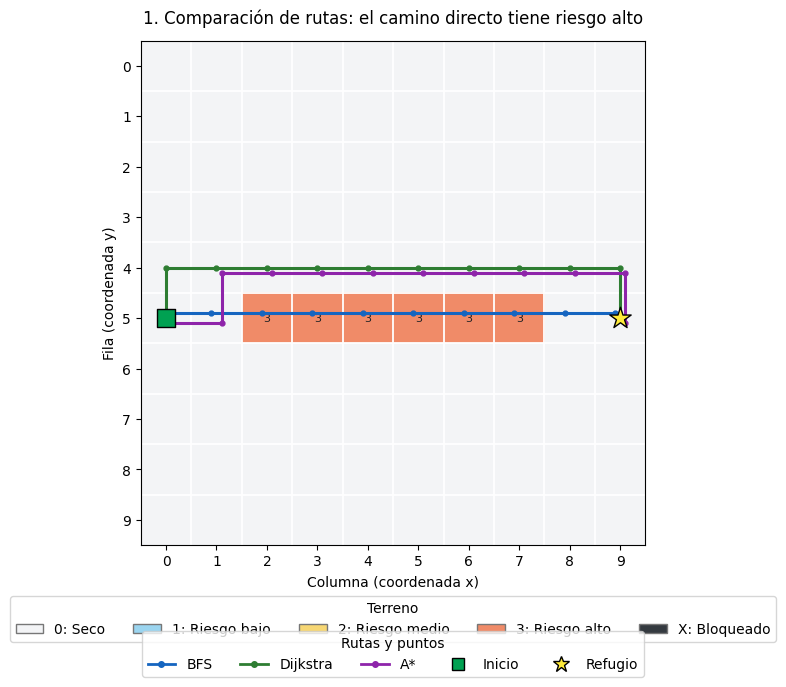

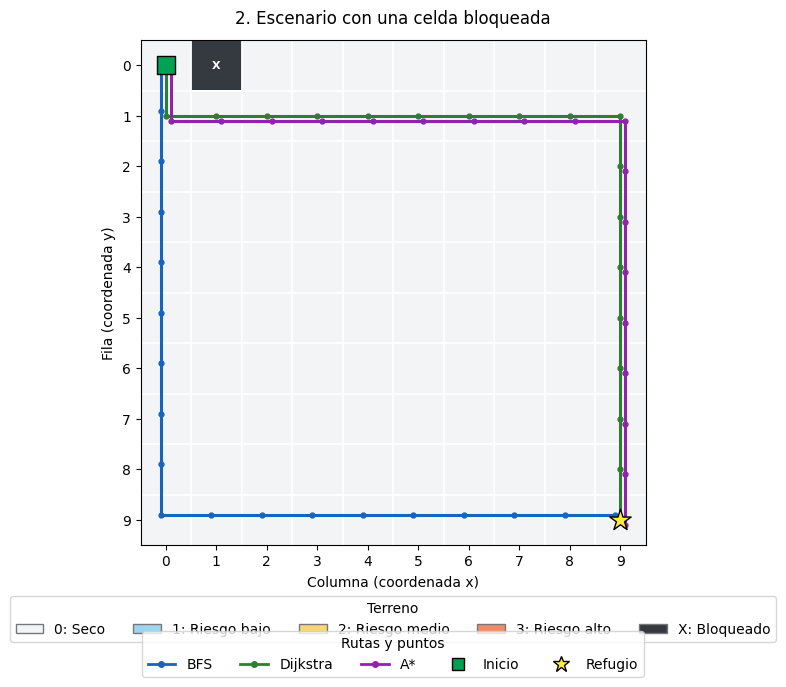

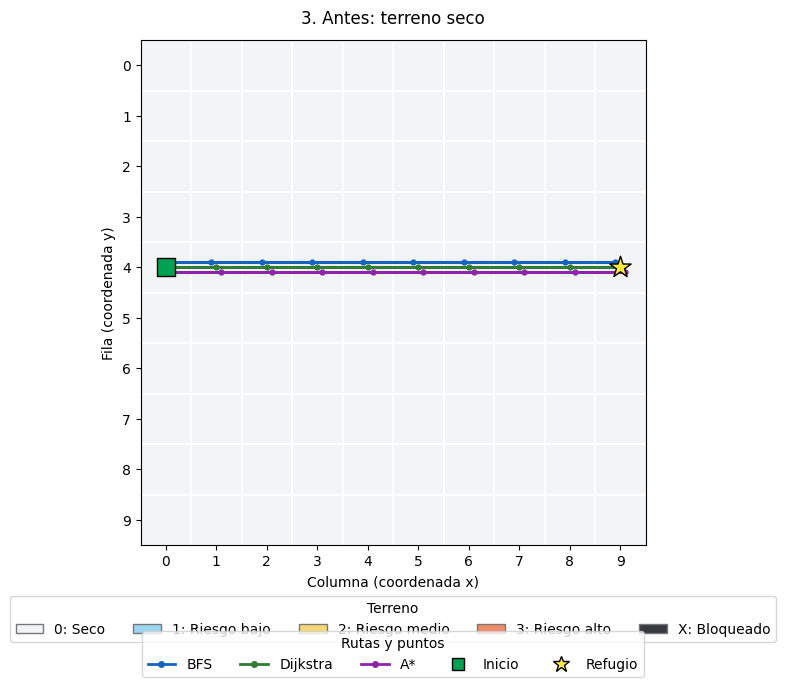

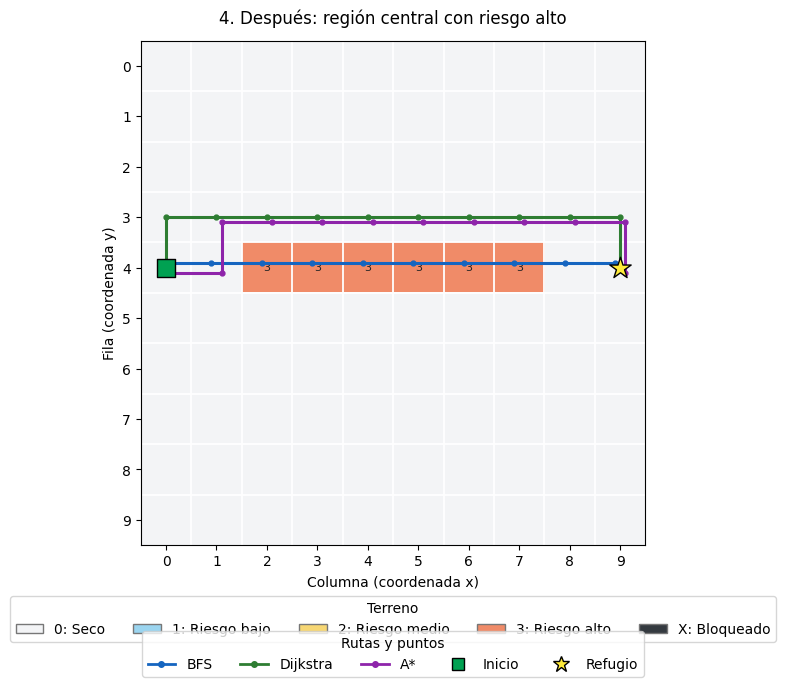

In [8]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from matplotlib.lines import Line2D


def graficar_mapa(terreno, resultados=None, inicio=None, refugio=None, titulo="Mapa de inundación"):
    codigos = {0: 0, 1: 1, 2: 2, 3: 3, BLOQUEADO: 4}
    matriz = [[codigos[v] for v in fila] for fila in terreno]
    colores_terreno = ["#f3f4f6", "#9bd5f0", "#f7d774", "#f08b68", "#343a40"]
    filas, columnas = len(terreno), len(terreno[0])

    # Tamaño proporcional para que se vea completa la matriz de 10x10 o mayor.
    fig, ax = plt.subplots(figsize=(max(9, columnas * 0.72), max(7, filas * 0.62)))
    ax.imshow(matriz, cmap=ListedColormap(colores_terreno), vmin=0, vmax=4, origin="upper")
    ax.set_xticks(range(columnas)); ax.set_yticks(range(filas))
    ax.set_xticks([x - 0.5 for x in range(1, columnas)], minor=True)
    ax.set_yticks([y - 0.5 for y in range(1, filas)], minor=True)
    ax.grid(which="minor", color="white", linewidth=1.3)
    ax.tick_params(which="minor", bottom=False, left=False)

    for r in range(filas):
        for c in range(columnas):
            valor = terreno[r][c]
            etiqueta = "X" if valor == BLOQUEADO else (str(valor) if valor in (1, 2, 3) else "")
            ax.text(c, r, etiqueta, ha="center", va="center",
                    color="white" if valor == BLOQUEADO else "#202124", fontsize=8, fontweight="bold" if valor == BLOQUEADO else "normal")

    colores_ruta = {"BFS": "#1565c0", "Dijkstra": "#2e7d32", "A*": "#8e24aa"}
    # Desplazamientos mínimos: si varias rutas usan la misma celda se distinguen mejor.
    desplazamientos = {"BFS": -0.10, "Dijkstra": 0.0, "A*": 0.10}
    if resultados:
        for nombre, resultado in resultados.items():
            camino = resultado.get("camino")
            if camino:
                ys = [p[0] + desplazamientos.get(nombre, 0) for p in camino]
                xs = [p[1] + desplazamientos.get(nombre, 0) for p in camino]
                ax.plot(xs, ys, marker="o", markersize=3.5, linewidth=2.2,
                        color=colores_ruta.get(nombre, "#d32f2f"), label=nombre, zorder=3)

    if inicio is not None:
        ax.scatter(inicio[1], inicio[0], marker="s", s=170, color="#00a152", edgecolors="black", label="Inicio", zorder=5)
    if refugio is not None:
        ax.scatter(refugio[1], refugio[0], marker="*", s=260, color="#ffeb3b", edgecolors="black", label="Refugio", zorder=5)

    leyenda_terreno = [
        Patch(facecolor=colores_terreno[0], edgecolor="#777777", label="0: Seco"),
        Patch(facecolor=colores_terreno[1], edgecolor="#777777", label="1: Riesgo bajo"),
        Patch(facecolor=colores_terreno[2], edgecolor="#777777", label="2: Riesgo medio"),
        Patch(facecolor=colores_terreno[3], edgecolor="#777777", label="3: Riesgo alto"),
        Patch(facecolor=colores_terreno[4], edgecolor="#777777", label="X: Bloqueado"),
    ]
    leyenda_rutas = []
    for nombre, color in colores_ruta.items():
        if resultados and nombre in resultados:
            leyenda_rutas.append(Line2D([0], [0], color=color, marker="o", linewidth=2, markersize=4, label=nombre))
    if inicio is not None: leyenda_rutas.append(Line2D([0], [0], marker="s", color="w", markerfacecolor="#00a152", markeredgecolor="black", markersize=9, label="Inicio"))
    if refugio is not None: leyenda_rutas.append(Line2D([0], [0], marker="*", color="w", markerfacecolor="#ffeb3b", markeredgecolor="black", markersize=12, label="Refugio"))

    ax.set_title(titulo, pad=12)
    ax.set_xlabel("Columna (coordenada x)"); ax.set_ylabel("Fila (coordenada y)")
    ax.set_xlim(-0.5, columnas - 0.5); ax.set_ylim(filas - 0.5, -0.5)
    ax.set_aspect("equal")
    fig.legend(handles=leyenda_terreno, loc="lower center", bbox_to_anchor=(0.5, 0.065), ncol=5, frameon=True, title="Terreno")
    if leyenda_rutas:
        fig.legend(handles=leyenda_rutas, loc="lower center", bbox_to_anchor=(0.5, 0.015), ncol=max(3, len(leyenda_rutas)), frameon=True, title="Rutas y puntos")
    fig.tight_layout(rect=[0, 0.13, 1, 1])
    plt.show()

# Gráfico 1: comparar las tres rutas cuando el camino directo tiene riesgo alto.
graficar_mapa(m5, r5, i5, f5, "1. Comparación de rutas: el camino directo tiene riesgo alto")
# Gráfico 2: comprobar el desvío cuando se bloquea una celda.
graficar_mapa(m2, r2, (0,0), (9,9), "2. Escenario con una celda bloqueada")
# Gráficos 3 y 4: comparar el terreno antes y después del cambio de riesgo.
graficar_mapa(m4a, antes, i4, f4, "3. Antes: terreno seco")
graficar_mapa(m4b, despues, i4, f4, "4. Después: región central con riesgo alto")

## 8. Resultados e interpretación para la entrega

- **BFS** encuentra una ruta con el menor número de movimientos cuando cada movimiento cuenta igual, pero no toma en cuenta el riesgo del terreno.
- **Dijkstra** compara el costo acumulado de los pasos y puede preferir un camino más largo si evita celdas peligrosas.
- **A\*** utiliza el costo acumulado y una estimación de la distancia restante. Con una heurística admisible y consistente, puede encontrar una ruta de costo óptimo con menos exploración que una búsqueda no informada en muchos mapas.
- Cuando se bloquea una celda, una ruta válida debe rodearla. Si el refugio queda completamente aislado, los algoritmos deben informar que no existe ruta.
- La prueba de entradas inválidas comprueba que el programa detecte coordenadas fuera del mapa, un inicio bloqueado y una matriz irregular.

**Conclusión:** en una evacuación simulada donde el riesgo tiene un costo, Dijkstra o A* son más apropiados que BFS para seleccionar una ruta de menor costo. Este modelo es didáctico: sus riesgos y costos son valores simulados y no sustituyen mapas oficiales, alertas ni instrucciones de protección civil.

## 9. Comparación cuantitativa mediante ejecuciones reales

Para que la comparación sea reproducible, se ejecuta cada algoritmo **30 veces** sobre el mismo escenario de prueba 5 (mapa de 10×10 con seis celdas de riesgo alto en la ruta directa). Se informa la mediana del tiempo en milisegundos y las métricas de trabajo. La mediana reduce la influencia de una ejecución excepcional, aunque el tiempo sigue dependiendo del equipo y del entorno.

La medida principal de trabajo será **nodos expandidos**; también se muestran nodos descubiertos e inserciones en la frontera. No conviene comparar algoritmos solo por tiempo en mapas pequeños: las diferencias pueden ser del orden de la variación normal del entorno.

In [9]:
from time import perf_counter
from statistics import median


def comparar_ejecuciones(mapa, inicio, refugio, repeticiones=30):
    """Compara las métricas algorítmicas y la mediana del tiempo real."""
    funciones = {
        "BFS": lambda: bfs(mapa, inicio, refugio),
        "Dijkstra": lambda: busqueda_costo(mapa, inicio, refugio),
        "A*": lambda: busqueda_costo(mapa, inicio, refugio, usar_heuristica=True),
    }
    filas = []
    for nombre, funcion in funciones.items():
        tiempos_ms = []
        resultado = None
        for _ in range(repeticiones):
            inicio_t = perf_counter()
            resultado = funcion()
            tiempos_ms.append((perf_counter() - inicio_t) * 1000)
        valido = validar_camino(resultado["camino"], mapa, inicio, refugio)[0] if resultado["camino"] else False
        filas.append({
            "Algoritmo": nombre,
            "Pasos": len(resultado["camino"]) - 1 if resultado["camino"] else None,
            "Costo de ruta": resultado["costo"],
            "Nodos expandidos": resultado["expandidos"],
            "Nodos descubiertos": resultado["descubiertos"],
            "Inserciones frontera": resultado["insertados_frontera"],
            "Tiempo mediano (ms)": round(median(tiempos_ms), 4),
            "Ruta válida": valido,
        })
    return filas


comparacion = comparar_ejecuciones(m5, i5, f5, repeticiones=30)
try:
    import pandas as pd
    tabla_comparacion = pd.DataFrame(comparacion)
    display(tabla_comparacion)
except ImportError:
    for fila in comparacion:
        print(fila)

# Aserciones de verificación: las tres rutas deben ser válidas y Dijkstra/A* no deben costar más que BFS en este escenario.
assert all(fila["Ruta válida"] for fila in comparacion)
por_algoritmo = {fila["Algoritmo"]: fila for fila in comparacion}
assert por_algoritmo["Dijkstra"]["Costo de ruta"] <= por_algoritmo["BFS"]["Costo de ruta"]
assert por_algoritmo["A*"]["Costo de ruta"] <= por_algoritmo["BFS"]["Costo de ruta"]
print(f"Comparación aprobada: {len(comparacion)} algoritmos, 30 ejecuciones por algoritmo, rutas válidas.")

,Algoritmo,Pasos,Costo de ruta,Nodos expandidos,Nodos descubiertos,Inserciones frontera,Tiempo mediano (ms),Ruta válida
0,BFS,9,69,75,84,84,0.0858,True
1,Dijkstra,11,11,82,94,94,0.1885,True
2,A*,11,11,24,50,50,0.0567,True


Comparación aprobada: 3 algoritmos, 30 ejecuciones por algoritmo, rutas válidas.


## 10. Decisiones de diseño

1. **Representación en matriz:** cada posición representa una celda y permite identificar con facilidad el terreno y los bloqueos. Coordenadas desde cero, expresadas como `(fila, columna)`.
2. **Movimientos ortogonales:** solo arriba, abajo, izquierda y derecha. Se excluyen diagonales para mantener reglas simples y evitar atravesar esquinas.
3. **Costo sensible al riesgo:** entrar en una celda tiene costo base 1 y una penalización según el nivel (seco: 0; bajo: 1; medio: 4; alto: 10). Estos valores son parámetros educativos y pueden cambiarse.
4. **Tres estrategias:** BFS sirve como referencia para el menor número de pasos; Dijkstra encuentra el mínimo costo acumulado; A* utiliza distancia Manhattan para orientar la búsqueda sin sobreestimar el costo mínimo restante.
5. **Validación antes de buscar:** evita que datos mal formados o coordenadas inválidas provoquen errores inesperados.
6. **Pruebas por escenarios:** se prueban ruta disponible, bloqueo, refugio aislado, cambio de riesgo, ruta directa de riesgo alto e inputs inválidos.
7. **Métricas:** el costo evalúa la calidad de la ruta; nodos expandidos/descubiertos e inserciones reflejan el trabajo de búsqueda; el tiempo mediano aporta una medida de rendimiento de la implementación.

## 11. Declaración de uso de herramientas de IA y verificación

**Declaración sugerida para la entrega:** Se utilizó ChatGPT como apoyo para proponer y revisar la estructura del código, documentar los algoritmos y sugerir pruebas. El código se verificó ejecutando las celdas del notebook, comprobando que las rutas empiezan en el origen, terminan en el refugio, usan movimientos adyacentes y evitan celdas bloqueadas. También se ejecutaron pruebas para una ruta inexistente y para entradas inválidas, y se compararon los costos, nodos expandidos y tiempos medidos. Las métricas de tiempo se obtienen al ejecutar el código y pueden variar según el entorno. La persona que entrega debe revisar el código y comprenderlo antes de presentarlo.

Ajusta esta declaración si usaste otras herramientas o realizaste verificaciones adicionales; no declares pruebas que no hayas ejecutado.

## 12. Registro de cambios con Git

El historial de Git debe registrar cambios reales hechos durante el desarrollo. Se recomienda documentar por lo menos la implementación inicial y la mejora de métricas/pruebas. En el repositorio adjunto se incluye un historial local de commits para reflejar esas etapas. Para registrar cambios nuevos, ejecuta `git status`, `git add`, `git commit` y `git log --oneline` desde la carpeta del proyecto.